<a href="https://colab.research.google.com/github/lucas-estanislau/pe-de-meia/blob/Analise-Explorat%C3%B3ria/03_analise.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive
import pandas as pd
drive.mount('/content/drive')

Mounted at /content/drive


## Analisando taxas de abandono de 2007 a 2025

In [ ]:
caminho = '/content/drive/MyDrive/pe-de-meia/inep/inep-data/taxas_em_uf_2007_2025.csv'

df_inep = pd.read_csv(caminho)
df_inep

,ANO,UF,TAXA_APROVACAO,TAXA_REPROVACAO,TAXA_ABANDONO
0,2007,AC,74.4,9.5,16.1
1,2007,AL,69.0,8.5,22.5
2,2007,AM,77.4,11.0,11.6
3,2007,AP,68.2,10.9,20.9
4,2007,BA,67.6,11.6,20.8
...,...,...,...,...,...
508,2025,RS,91.3,6.1,2.6
509,2025,SC,88.8,7.3,3.9
510,2025,SE,94.0,4.2,1.8
511,2025,SP,93.7,2.8,3.5


In [ ]:
anos = [2022, 2023, 2024, 2025]

df_comparacao = df_inep[
    df_inep["ANO"].isin(anos)
].copy()

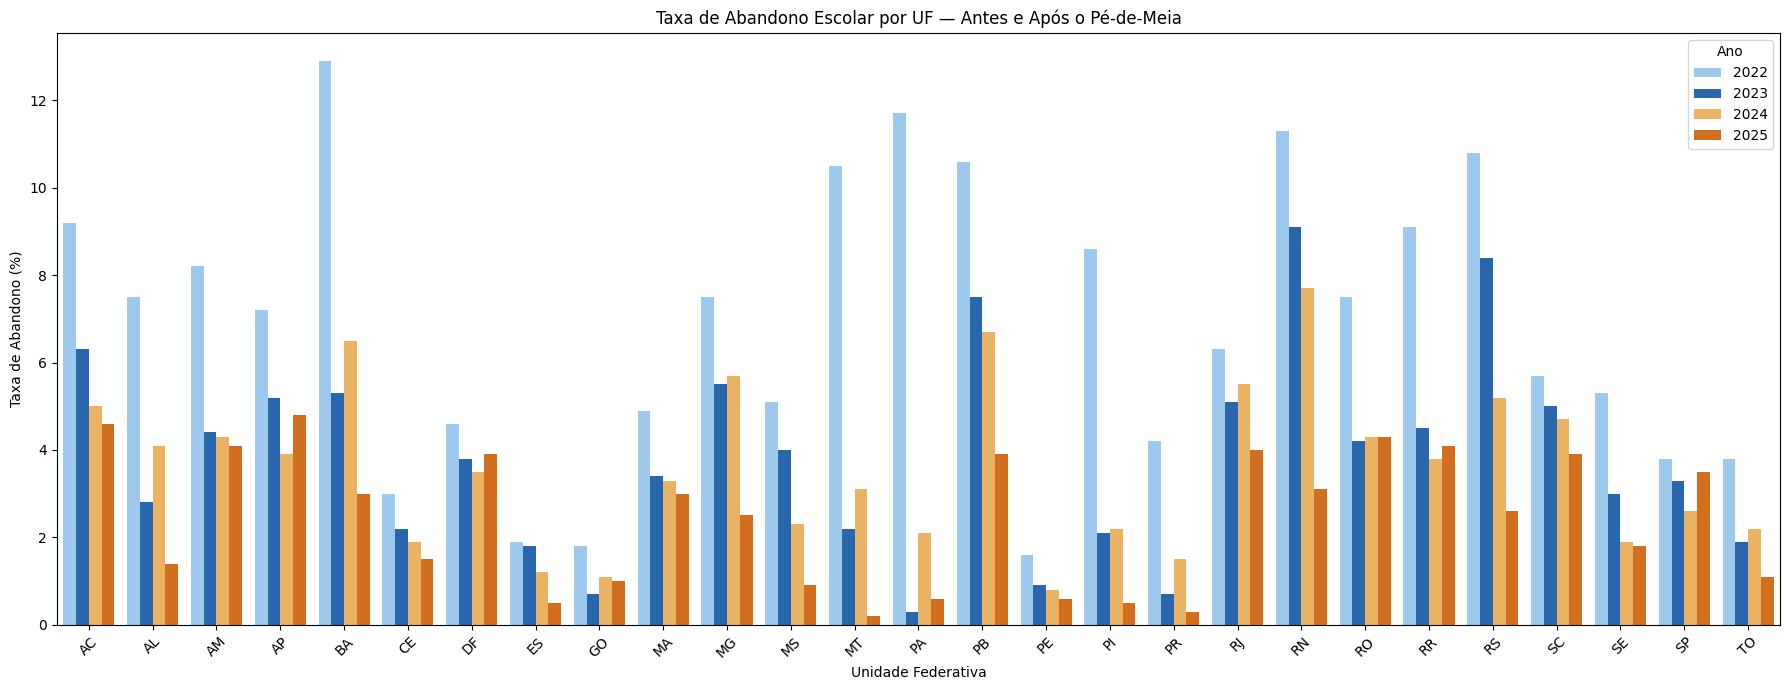

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(18, 7))

sns.barplot(
    data=df_comparacao,
    x="UF",
    y="TAXA_ABANDONO",
    hue="ANO",
    hue_order=[2022, 2023, 2024, 2025],
    dodge=True,
    palette={
        2022: "#90CAF9",
        2023: "#1565C0",
        2024: "#FFB74D",
        2025: "#EF6C00"
    },
    errorbar=None
)

plt.title("Taxa de Abandono Escolar por UF — Antes e Após o Pé-de-Meia")
plt.xlabel("Unidade Federativa")
plt.ylabel("Taxa de Abandono (%)")
plt.legend(title="Ano")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
df_periodos = df_comparacao.copy()

df_periodos["PERIODO"] = df_periodos["ANO"].apply(
    lambda ano: "Antes" if ano <= 2023 else "Depois"
)

df_medias = (
    df_periodos
    .groupby(["UF", "PERIODO"])["TAXA_ABANDONO"]
    .mean()
    .unstack()
    .reset_index()
)

df_medias["DIFERENCA"] = (
    df_medias["Depois"] - df_medias["Antes"]
)

df_medias = df_medias.sort_values("DIFERENCA")

display(df_medias)

PERIODO,UF,Antes,Depois,DIFERENCA
22,RS,9.60,3.90,-5.70
19,RN,10.20,5.40,-4.80
12,MT,6.35,1.65,-4.70
13,PA,6.00,1.35,-4.65
4,BA,9.10,4.75,-4.35
16,PI,5.35,1.35,-4.00
14,PB,9.05,5.30,-3.75
11,MS,4.55,1.60,-2.95
0,AC,7.75,4.80,-2.95
21,RR,6.80,3.95,-2.85


In [ ]:
caminho = "/content/drive/MyDrive/pe-de-meia/agregados/pdm-tx-rendimento-2024-2025.csv"

df_final = pd.read_csv(caminho)

df_final

,ANO,UF,VALOR_TOTAL,QUANTIDADE_PAGAMENTOS,TAXA_APROVACAO,TAXA_REPROVACAO,TAXA_ABANDONO
0,2024,AC,3.844802e+07,191904,86.8,8.2,5.0
1,2024,AL,1.462447e+08,729120,90.2,5.7,4.1
2,2024,AM,1.555299e+08,776280,89.2,6.5,4.3
3,2024,AP,3.629368e+07,181301,88.0,8.1,3.9
4,2024,BA,6.058837e+08,3018872,88.4,5.1,6.5
5,2024,CE,4.160727e+08,2078405,96.9,1.2,1.9
6,2024,DF,5.456692e+07,272775,86.4,10.1,3.5
7,2024,ES,7.818292e+07,390554,96.5,2.3,1.2
8,2024,GO,1.405325e+08,701655,96.9,2.0,1.1
9,2024,MA,3.647820e+08,1821065,92.1,4.6,3.3


In [ ]:
df2024 = df_final.loc[df_final['ANO'] == 2024].reset_index()
df2024['TAXA_ABANDONO'].astype(float)
df2024

,index,ANO,UF,VALOR_TOTAL,QUANTIDADE_PAGAMENTOS,TAXA_APROVACAO,TAXA_REPROVACAO,TAXA_ABANDONO
0,0,2024,AC,38448025.0,191904,86.8,8.2,5.0
1,1,2024,AL,146244725.0,729120,90.2,5.7,4.1
2,2,2024,AM,155529925.0,776280,89.2,6.5,4.3
3,3,2024,AP,36293675.0,181301,88.0,8.1,3.9
4,4,2024,BA,605883725.0,3018872,88.4,5.1,6.5
5,5,2024,CE,416072725.0,2078405,96.9,1.2,1.9
6,6,2024,DF,54566925.0,272775,86.4,10.1,3.5
7,7,2024,ES,78182925.0,390554,96.5,2.3,1.2
8,8,2024,GO,140532500.0,701655,96.9,2.0,1.1
9,9,2024,MA,364782025.0,1821065,92.1,4.6,3.3


In [ ]:
df2025 = df_final.loc[df_final['ANO'] == 2025].reset_index()
df2025['TAXA_ABANDONO'].astype(float)
df2025

,index,ANO,UF,VALOR_TOTAL,QUANTIDADE_PAGAMENTOS,TAXA_APROVACAO,TAXA_REPROVACAO,TAXA_ABANDONO
0,27,2025,AC,7.535052e+07,286595,89.2,6.2,4.6
1,28,2025,AL,2.739513e+08,1022348,95.9,2.7,1.4
2,29,2025,AM,4.194634e+08,1609164,89.4,6.5,4.1
3,30,2025,AP,7.053230e+07,273647,90.1,5.1,4.8
4,31,2025,BA,1.105413e+09,4154600,92.4,4.6,3.0
5,32,2025,CE,7.770466e+08,2817457,97.5,1.0,1.5
6,33,2025,DF,1.068086e+08,399980,82.4,13.7,3.9
7,34,2025,ES,1.628706e+08,601123,98.4,1.1,0.5
8,35,2025,GO,3.159621e+08,1167785,97.8,1.2,1.0
9,36,2025,MA,6.525316e+08,2451427,93.2,3.8,3.0


In [ ]:
dfmedia = pd.DataFrame()
dfmedia['ABANDONO_2024'] = df2024['TAXA_ABANDONO']
dfmedia['ABANDONO_2025'] = df2025['TAXA_ABANDONO']
dfmedia['DIFERENCA_ABANDONO'] = df2025['TAXA_ABANDONO'] - df2024['TAXA_ABANDONO']
dfmedia

,ABANDONO_2024,ABANDONO_2025,DIFERENCA_ABANDONO
0,5.0,4.6,-0.4
1,4.1,1.4,-2.7
2,4.3,4.1,-0.2
3,3.9,4.8,0.9
4,6.5,3.0,-3.5
5,1.9,1.5,-0.4
6,3.5,3.9,0.4
7,1.2,0.5,-0.7
8,1.1,1.0,-0.1
9,3.3,3.0,-0.3


In [ ]:
dfmedia['DIFERENCA_ABANDONO'].mean()

np.float64(-1.162962962962963)

In [ ]:
# Quantas UFs reduziram a taxa de abandono?
reduziram = (dfmedia["DIFERENCA_ABANDONO"] < 0).sum()

# Quantas aumentaram?
aumentaram = (dfmedia["DIFERENCA_ABANDONO"] > 0).sum()

# Quantas permaneceram iguais?
iguais = (dfmedia["DIFERENCA_ABANDONO"] == 0).sum()

print("UFs que reduziram:", reduziram)
print("UFs que aumentaram:", aumentaram)
print("UFs sem alteração:", iguais)

UFs que reduziram: 22
UFs que aumentaram: 4
UFs sem alteração: 1


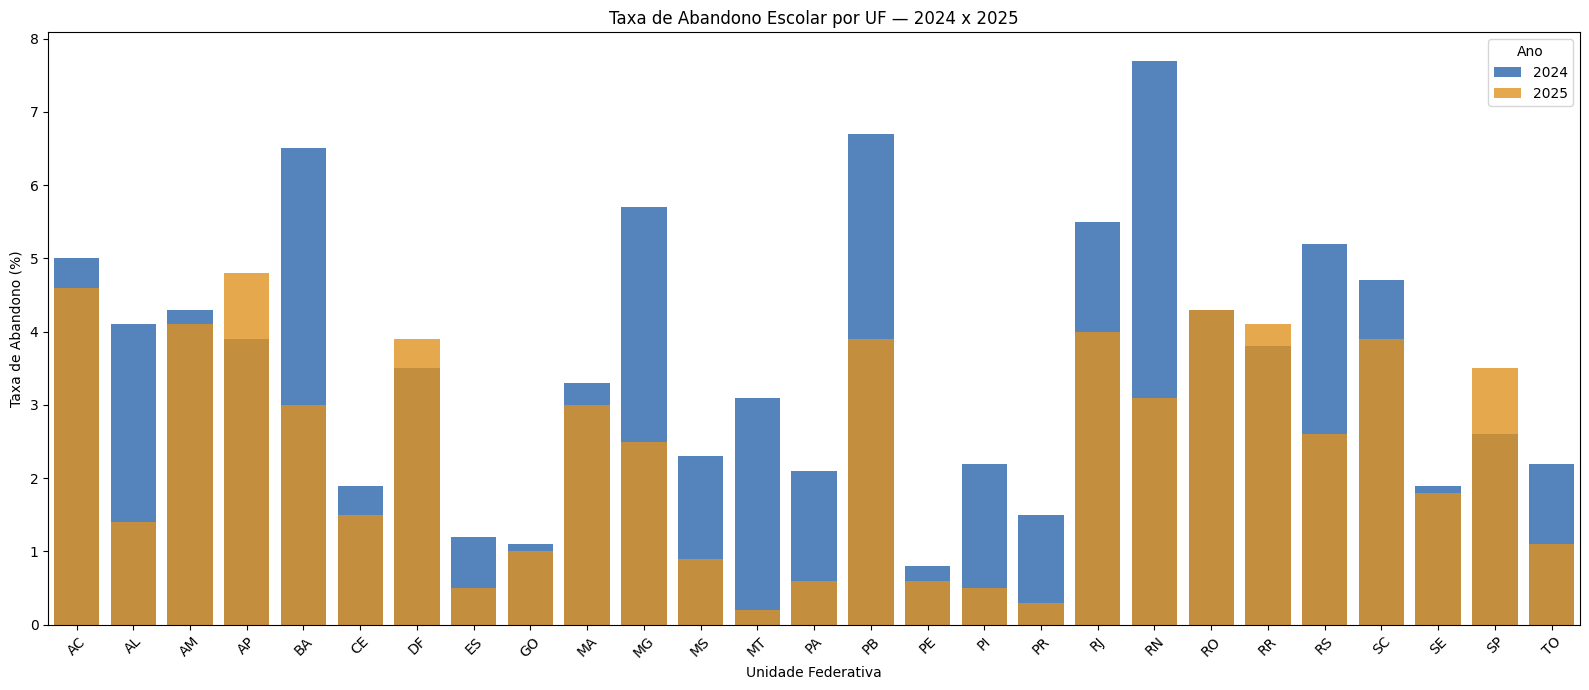

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(16, 7))

sns.barplot(
    data=df_final,
    x="UF",
    y="TAXA_ABANDONO",
    hue="ANO",
    dodge=False,
    palette={
      2024: "#1565C0",
      2025: "#FF9800"
    },
    alpha=0.8,
    errorbar=None
)

plt.title("Taxa de Abandono Escolar por UF — 2024 x 2025")
plt.xlabel("Unidade Federativa")
plt.ylabel("Taxa de Abandono (%)")
plt.legend(title="Ano")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

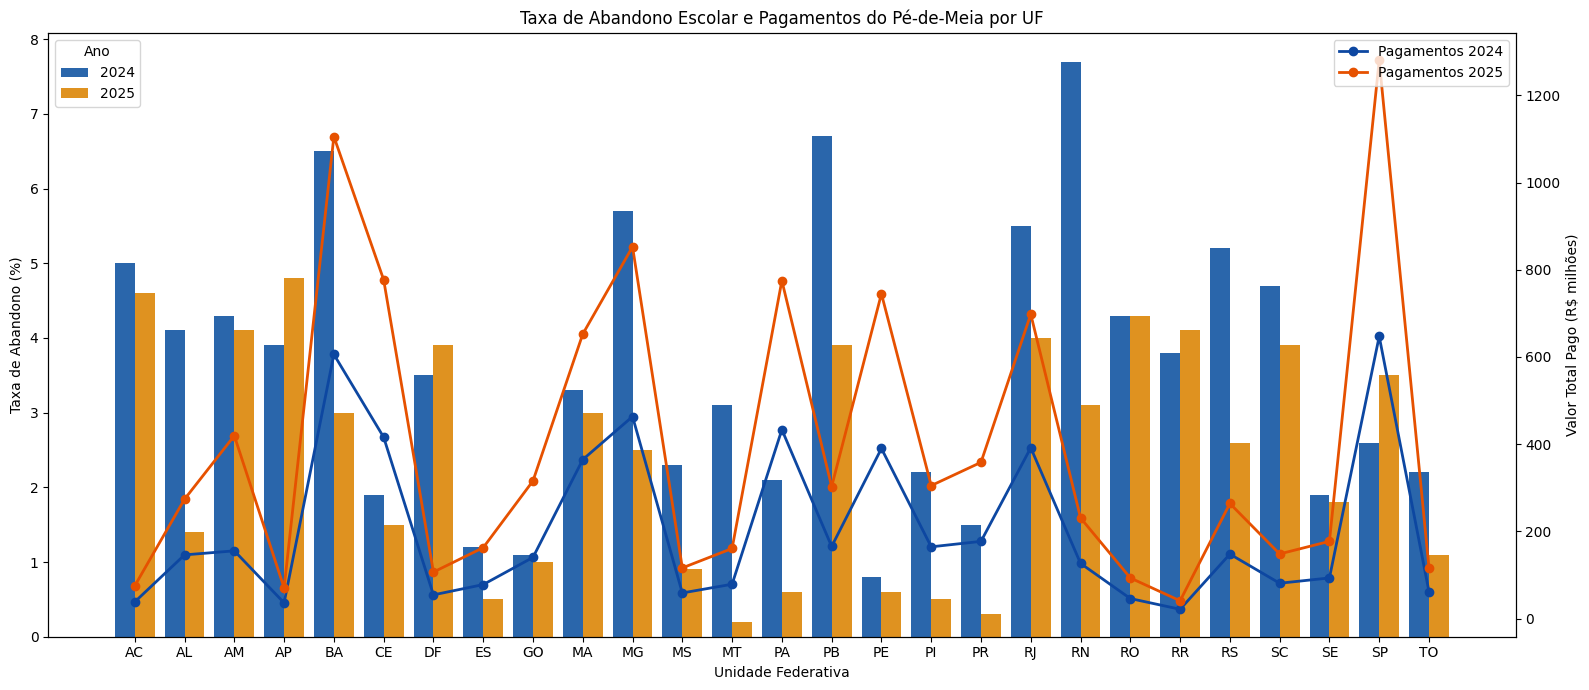

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Filtrar dados
df_grafico = df_final[
    df_final["ANO"].isin([2024, 2025])
].copy()

# Criar figura e eixo principal
fig, ax1 = plt.subplots(figsize=(16, 7))

# Barras: taxa de abandono
sns.barplot(
    data=df_grafico,
    x="UF",
    y="TAXA_ABANDONO",
    hue="ANO",
    palette={
        2024: "#1565C0",
        2025: "#FF9800"
    },
    errorbar=None,
    ax=ax1
)

ax1.set_xlabel("Unidade Federativa")
ax1.set_ylabel("Taxa de Abandono (%)")
ax1.legend(title="Ano", loc="upper left")

# Criar segundo eixo Y
ax2 = ax1.twinx()

# Ordenar as UFs conforme o eixo das barras
ufs = list(dict.fromkeys(df_grafico["UF"]))

# Linha para cada ano
for ano, cor in [(2024, "#0D47A1"), (2025, "#E65100")]:

    dados_ano = (
        df_grafico[df_grafico["ANO"] == ano]
        .set_index("UF")
        .reindex(ufs)
    )

    ax2.plot(
        range(len(ufs)),
        dados_ano["VALOR_TOTAL"] / 1_000_000,
        color=cor,
        marker="o",
        linewidth=2,
        label=f"Pagamentos {ano}"
    )

ax2.set_ylabel("Valor Total Pago (R$ milhões)")
ax2.legend(loc="upper right")

plt.title("Taxa de Abandono Escolar e Pagamentos do Pé-de-Meia por UF")
plt.tight_layout()
plt.show()

In [ ]:
df_final.loc[(df_final['UF'] == 'SP') | (df_final['UF'] == 'BA')]

,ANO,UF,VALOR_TOTAL,QUANTIDADE_PAGAMENTOS,TAXA_APROVACAO,TAXA_REPROVACAO,TAXA_ABANDONO
4,2024,BA,6.058837e+08,3018872,88.4,5.1,6.5
25,2024,SP,6.472612e+08,3235801,94.0,3.4,2.6
31,2025,BA,1.105413e+09,4154600,92.4,4.6,3.0
52,2025,SP,1.280234e+09,4520212,93.7,2.8,3.5


In [ ]:
df_final.loc[df_final['VALOR_TOTAL'] > 1000000000]

,ANO,UF,VALOR_TOTAL,QUANTIDADE_PAGAMENTOS,TAXA_APROVACAO,TAXA_REPROVACAO,TAXA_ABANDONO
31,2025,BA,1.105413e+09,4154600,92.4,4.6,3.0
52,2025,SP,1.280234e+09,4520212,93.7,2.8,3.5


## Análise dos dados do INEP

In [ ]:
caminho = '/content/drive/MyDrive/pe-de-meia/inep/inep-data/taxas_em_uf_2007_2025.csv'

In [ ]:
df_inep = pd.read_csv(caminho)
df_inep.head()

,ANO,UF,TAXA_APROVACAO,TAXA_REPROVACAO,TAXA_ABANDONO
0,2007,AC,74.4,9.5,16.1
1,2007,AL,69.0,8.5,22.5
2,2007,AM,77.4,11.0,11.6
3,2007,AP,68.2,10.9,20.9
4,2007,BA,67.6,11.6,20.8


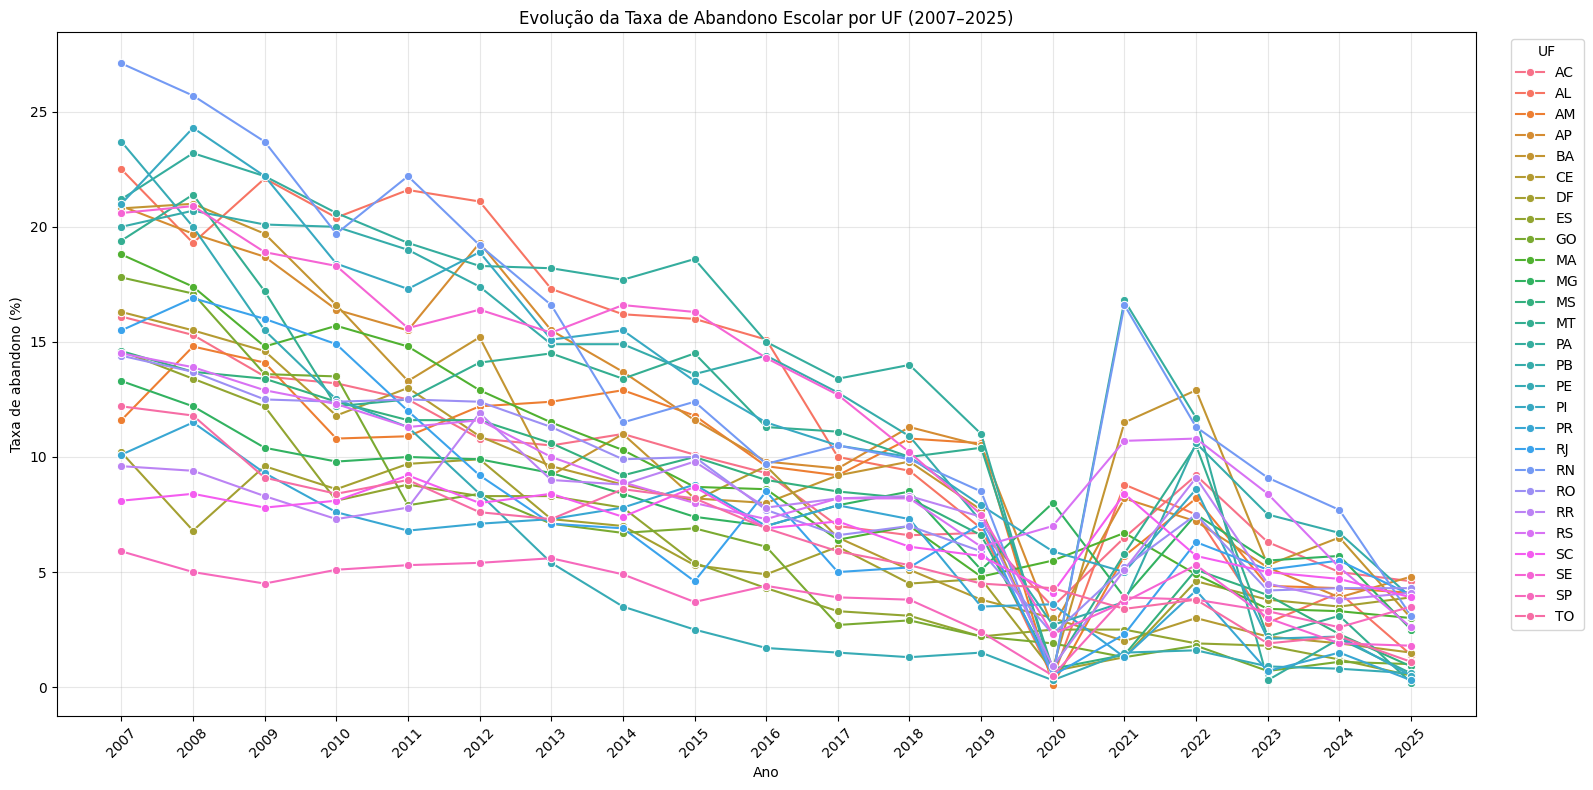

In [ ]:
plt.figure(figsize=(16, 8))

sns.lineplot(
    data=df_inep,
    x="ANO",
    y="TAXA_ABANDONO",
    hue="UF",
    marker="o",
    estimator=None
)

plt.title("Evolução da Taxa de Abandono Escolar por UF (2007–2025)")
plt.xlabel("Ano")
plt.ylabel("Taxa de abandono (%)")

plt.xticks(range(2007, 2026), rotation=45)
plt.grid(True, alpha=0.3)

plt.legend(
    title="UF",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

In [ ]:
import plotly.express as px

fig = px.line(
    df_inep.sort_values(["UF", "ANO"]),
    x="ANO",
    y="TAXA_ABANDONO",
    color="UF",
    markers=True,
    category_orders={
        "UF": sorted(df_inep["UF"].unique())
    },
    title="Evolução da Taxa de Abandono Escolar por UF (2007–2025)",
    labels={
        "ANO": "Ano",
        "TAXA_ABANDONO": "Taxa de Abandono (%)",
        "UF": "Estado"
    }
)

fig.update_layout(
    width=1200,
    height=650,
    hovermode="x unified",
    legend_title="UF"
)

fig.update_xaxes(dtick=1)

# Período da pandemia e seus desdobramentos (2020–2023)
fig.add_vrect(
    x0=2019.5,
    x1=2023.5,
    fillcolor="lightcoral",
    opacity=0.20,
    layer="below",
    line_width=0,
    annotation_text="Pandemia e pós-pandemia",
    annotation_position="top left",
    annotation_font_size=12,
    annotation_font_color="darkred"
)

# Período do Pé-de-Meia (2024–2025)
fig.add_vrect(
    x0=2023.5,
    x1=2025.5,
    fillcolor="lightgreen",
    opacity=0.25,
    layer="below",
    line_width=0,
    annotation_text="Pé-de-Meia",
    annotation_position="top left",
    annotation_font_size=12,
    annotation_font_color="darkgreen"
)

fig.update_traces(visible="legendonly")
fig.show()

Há uma anomalia do período de 2019 a 2021. As taxas de abandono da maioria das UFs despenca o ano de 2020 e volta a subir bruscamente em 2021. O motivo provavelmente está relacionado à pandemia de Covid-19 e às mudanças que ocorreram na forma como as escolas avaliaram e acompanharam os estudantes.

In [ ]:
import plotly.express as px

fig = px.line(
    df_inep,
    x="ANO",
    y="TAXA_APROVACAO",
    color="UF",
    markers=True,
    title="Evolução da Taxa de Aprovação Escolar por UF (2007–2025)",
    labels={
        "ANO": "Ano",
        "TAXA_APROVACAO": "Taxa de aprovação (%)",
        "UF": "Estado"
    }
)

# Inicia com todas as linhas ocultas
fig.update_traces(visible="legendonly")

# Sombreamento da pandemia (2020–2023)
fig.add_vrect(
    x0=2019.5,
    x1=2023.5,
    fillcolor="red",
    opacity=0.10,
    line_width=0,
    annotation_text="Pandemia e pós-pandemia",
    annotation_position="top left"
)

# Sombreamento do Pé-de-Meia (2024–2025)
fig.add_vrect(
    x0=2023.5,
    x1=2025.5,
    fillcolor="green",
    opacity=0.12,
    line_width=0,
    annotation_text="Pé-de-Meia",
    annotation_position="top left"
)

fig.update_layout(
    width=1100,
    height=600,
    hovermode="x unified",
    xaxis=dict(
        tickmode="linear",
        tick0=2007,
        dtick=1,
        range=[2006.5, 2025.5]
    ),
    yaxis=dict(
        title="Taxa de aprovação (%)",
        range=[0, 100]
    ),
    legend=dict(
        title="Selecione os estados",
        x=1.02,
        y=1
    )
)

fig.show()

Como é possível observar, a taxa de aprovação apresenta um pico de 2019 para 2020, o que pode possivelmente estar relacionado a regras menos rígidas para aprovação na maioria das UFs. Consequentemente, isso contribui para uma menor taxa de abandono.